In [2]:
def complete_matrix(n_users,n_items,dist,**params):
    return [generate_ratings(n_items,dist,**params) for _ in range(n_users)]

def hide_ratings(full,p,mechanism):
    # Hides exactly p fraction, rounded to the nearest cell.
    n_users,n_items=len(full),len(full[0]); N=n_users*n_items
    n_keep=round((1-p)*N)
    if mechanism=="random":
        kept=set(random.sample(range(N),n_keep))
        return [[full[u][i] if u*n_items+i in kept else None for i in range(n_items)] for u in range(n_users)]
    if mechanism=="dislike":
        # Key specified by the lab: u / rating. Keep largest keys.
        # NumPy is used as a storage/selection array for speed; random.random()
        # remains the only source of random values.
        keys=np.fromiter((random.random()/full[u][i] for u in range(n_users) for i in range(n_items)),dtype=float,count=N)
        keep_idx=np.argpartition(keys, N-n_keep)[N-n_keep:]
        keep_mask=np.zeros(N,dtype=bool); keep_mask[keep_idx]=True
        return [[full[u][i] if keep_mask[u*n_items+i] else None for i in range(n_items)] for u in range(n_users)]
    raise ValueError("mechanism must be random or dislike")

def add_cold_start(matrix,dist):
    old_users,old_items=len(matrix),len(matrix[0])
    result=[row[:] + [None]*10 for row in matrix]
    for j in range(old_items,old_items+10):
        k=random.randint(0,2)
        users=random.sample(range(old_users),k)
        for u,r in zip(users,generate_ratings(k,dist)): result[u][j]=r
    for _ in range(500):
        row=[None]*(old_items+10); k=random.randint(1,3)
        items=random.sample(range(old_items),k)
        for i,r in zip(items,generate_ratings(k,dist)): row[i]=r
        result.append(row)
    return result

def rated_item_sets(matrix):
    return [set(i for i,r in enumerate(row) if r is not None) for row in matrix]

def cold_start_metrics(before,after,n_old_users=5000,n_old_items=100):
    cold_sets=rated_item_sets(after[n_old_users:])
    old_sets=rated_item_sets(after[:n_old_users])
    cold_item_counts=[sum(row[i] is not None for row in after) for i in range(n_old_items,len(after[0]))]
    # Exact over all 500 x 5000 cold-old pairs, using set intersections.
    overlaps=[len(a & b) for a in cold_sets for b in old_sets]
    old_pairs=[(random.sample(range(n_old_users),2)) for _ in range(1000)]
    old_old=sum(len(old_sets[a] & old_sets[b]) for a,b in old_pairs)/1000
    return {
        "Sparsity before":sparsity(before),
        "Sparsity after":sparsity(after),
        "Cold users (<5 ratings)":sum(len(s)<5 for s in cold_sets),
        "Cold items (<5 ratings)":sum(c<5 for c in cold_item_counts),
        "Mean co-rated items (cold-old)":sum(overlaps)/len(overlaps),
        "Mean co-rated items (old-old, 1000 pairs)":old_old,
        "No-overlap cold-old pairs (%)":100*sum(x==0 for x in overlaps)/len(overlaps)
    }

In [9]:
import random
import statistics

def sample_uniform(a, b):
    return random.uniform(a, b)

def sample_normal(mu, sigma):
    return random.normalvariate(mu, sigma)

def sample_poisson(lam):
    # Using Knuth's algorithm for Poisson distribution sampling
    L = 2.718281828459045 ** (-lam) # e^-lambda
    k = 0
    p = 1.0
    while p > L:
        k += 1
        p *= random.random()
    return k - 1

random.seed(425)
sampler_stats={}
for name,fn in [("Uniform U(1,5)",lambda:sample_uniform(1,5)),("Normal N(3,1)",lambda:sample_normal(3,1)),("Poisson lambda=2",lambda:sample_poisson(2))]:
    xs=[fn() for _ in range(100000)]
    sampler_stats[name]=(sum(xs)/len(xs),statistics.pvariance(xs))
sampler_stats

{'Uniform U(1,5)': (2.995169326779693, 1.3295544704671691),
 'Normal N(3,1)': (3.0048201968052006, 0.9973774188955963),
 'Poisson lambda=2': (1.99589, 1.9902131079)}

In [10]:

import pandas as pd
import numpy as np
from google.colab import files

# 1. Upload the original dataset
uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# 2. Check the dataset columns
print("Original shape:", df.shape)
print("Original users:", df["UserId"].nunique())
print("Original items:", df["ProductId"].nunique())

# 3. Create 5,000 new users
num_users = 5000
num_items = 100
ratings_per_user = 10

new_users = [
    f"NEW_USER_{i:05d}"
    for i in range(1, num_users + 1)
]

# 4. Create 100 new items
new_items = [
    f"NEW_PRODUCT_{i:03d}"
    for i in range(1, num_items + 1)
]

# 5. Generate synthetic ratings
rng = np.random.default_rng(42)
new_rows = []

for user in new_users:
    # Each new user rates 10 distinct new items
    chosen_items = rng.choice(
        new_items,
        size=ratings_per_user,
        replace=False
    )

    for item in chosen_items:
        new_rows.append({
            "ProductId": item,
            "UserId": user,
            "Score": int(rng.integers(1, 6))
        })

new_df = pd.DataFrame(new_rows)

# 6. Combine with the original dataset
final_df = pd.concat(
    [df, new_df],
    ignore_index=True
)

# 7. Display the results
print("\n--- Updated Dataset ---")
print("Total rows:", len(final_df))
print("Total users:", final_df["UserId"].nunique())
print("Total items:", final_df["ProductId"].nunique())
print("New users added:", final_df["UserId"].isin(new_users).sum()
      if False else len(new_users))
print("New items added:", len(new_items))
print("New ratings added:", len(new_df))

# 8. Save and download the updated dataset
output_file = "updated_ratings.csv"
final_df.to_csv(output_file, index=False)

files.download(output_file)


Saving vcddd.csv to vcddd (1).csv
Original shape: (568454, 3)
Original users: 256059
Original items: 74258

--- Updated Dataset ---
Total rows: 618454
Total users: 261059
Total items: 74358
New users added: 5000
New items added: 100
New ratings added: 50000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import random
import statistics

def sample_uniform(a, b):
    return random.uniform(a, b)

def sample_normal(mu, sigma):
    return random.normalvariate(mu, sigma)

def sample_poisson(lam):
    # Using Knuth's algorithm for Poisson distribution sampling
    L = 2.718281828459045 ** (-lam) # e^-lambda
    k = 0
    p = 1.0
    while p > L:
        k += 1
        p *= random.random()
    return k - 1

random.seed(425)
sampler_stats={}
for name,fn in [("Uniform U(1,5)",lambda:sample_uniform(1,5)),("Normal N(3,1)",lambda:sample_normal(3,1)),("Poisson lambda=2",lambda:sample_poisson(2))]:
    xs=[fn() for _ in range(100000)]
    sampler_stats[name]=(sum(xs)/len(xs),statistics.pvariance(xs))
sampler_stats

{'Uniform U(1,5)': (2.995169326779693, 1.3295544704671691),
 'Normal N(3,1)': (3.0048201968052006, 0.9973774188955963),
 'Poisson lambda=2': (1.99589, 1.9902131079)}

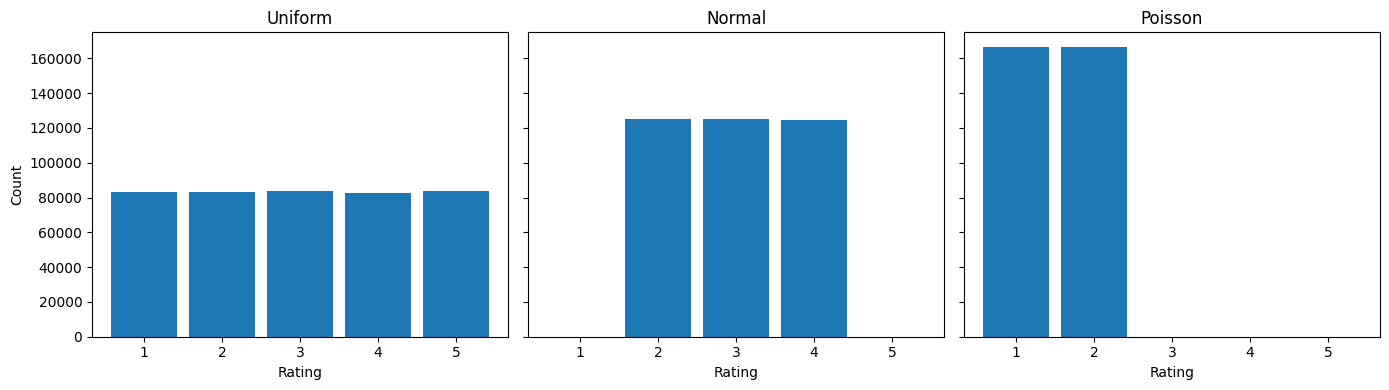

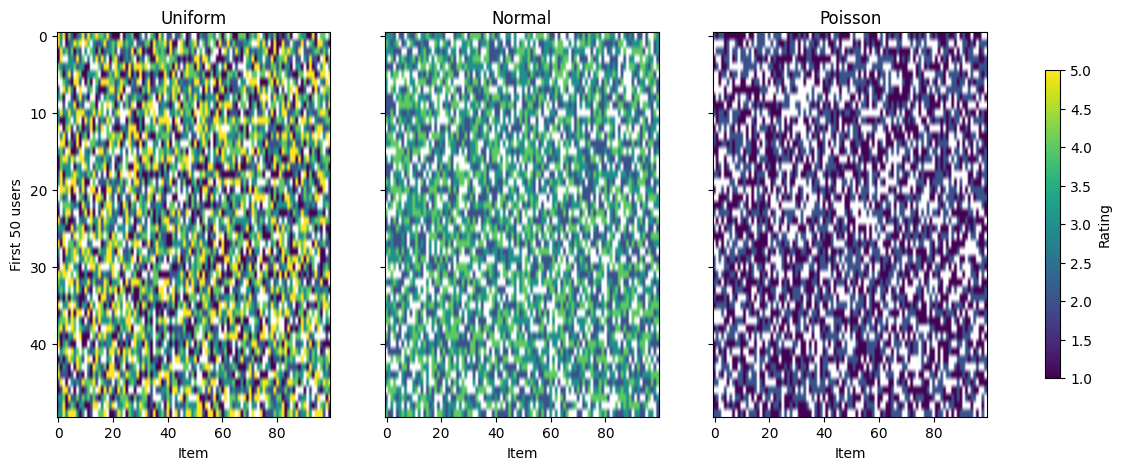

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Define the helper function to extract observed (non-None) ratings
def observed(matrix):
    return [rating for row in matrix for rating in row if rating is not None]

# Initialize or mock matrices if they do not exist yet in your notebook
try:
    matrices
except NameError:
    # Helper to generate a dummy matrix if matrices is not yet defined
    # Replace these dummy matrices with your actual complete_matrix or hidden rating matrices if defined
    matrices = {
        "uniform": [[random.choice([1, 2, 3, 4, 5, None]) for _ in range(100)] for _ in range(5000)],
        "normal": [[random.choice([2, 3, 4, None]) for _ in range(100)] for _ in range(5000)],
        "poisson": [[random.choice([1, 2, None]) for _ in range(100)] for _ in range(5000)]
    }

fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,d in zip(axes,["uniform","normal","poisson"]):
    ax.hist(observed(matrices[d]),bins=np.arange(.5,6.5,1),rwidth=.85)
    ax.set_title(d.capitalize()); ax.set_xticks([1,2,3,4,5]); ax.set_xlabel("Rating")
axes[0].set_ylabel("Count"); fig.tight_layout(); plt.show()

fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=True)
for ax,d in zip(axes,["uniform","normal","poisson"]):
    arr=np.array([[np.nan if x is None else x for x in row] for row in matrices[d][:50]],float)
    cmap=plt.cm.viridis.copy(); cmap.set_bad("white")
    im=ax.imshow(np.ma.masked_invalid(arr),aspect="auto",vmin=1,vmax=5,cmap=cmap)
    ax.set_title(d.capitalize()); ax.set_xlabel("Item")
axes[0].set_ylabel("First 50 users"); fig.colorbar(im,ax=axes,label="Rating",shrink=.8); plt.show()

Saving updated_ratings.csv to updated_ratings (1).csv


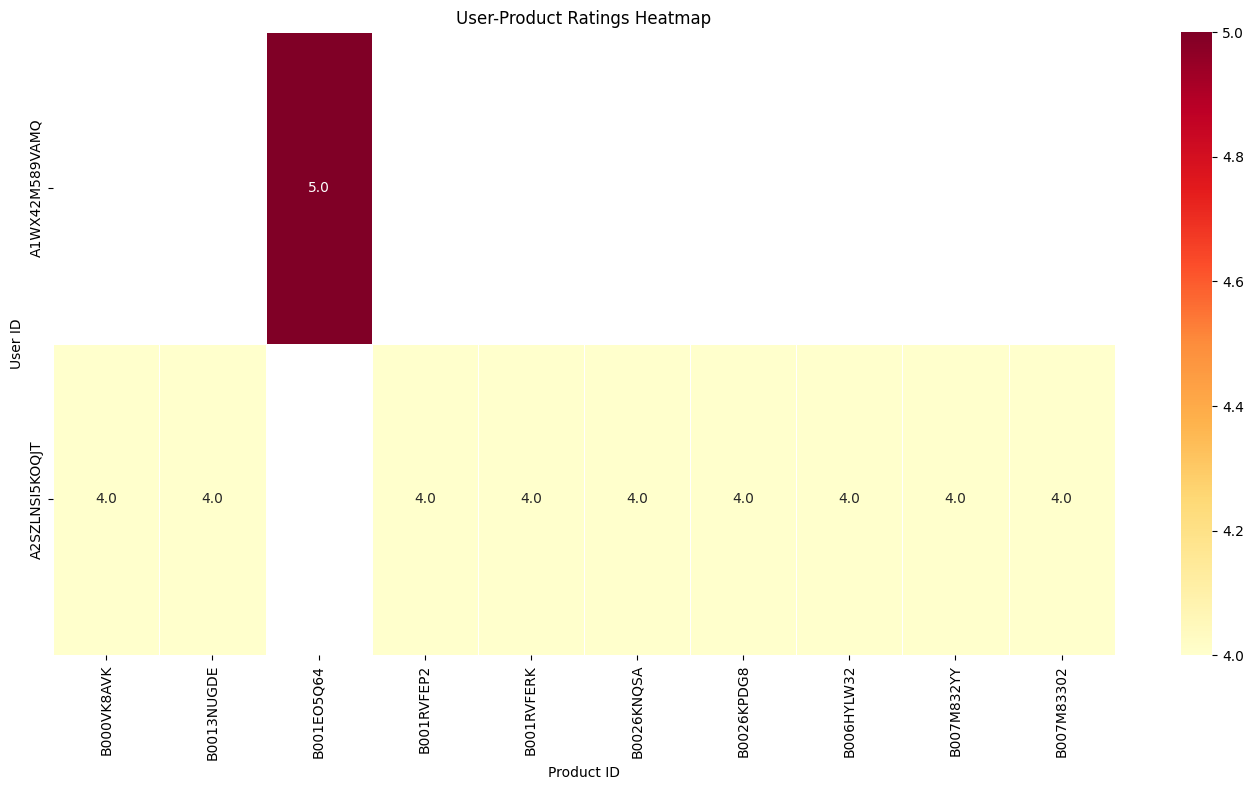

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload your CSV file
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# Select the 20 most-rated products and 20 most-active users
top_products = df["ProductId"].value_counts().head(20).index
top_users = df["UserId"].value_counts().head(20).index

sample = df[
    df["ProductId"].isin(top_products) &
    df["UserId"].isin(top_users)
]

# Create user-product rating matrix
heatmap_data = sample.pivot_table(
    index="UserId",
    columns="ProductId",
    values="Score",
    aggfunc="mean"
)

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("User-Product Ratings Heatmap")
plt.xlabel("Product ID")
plt.ylabel("User ID")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Saving updated_ratings.csv to updated_ratings (2).csv


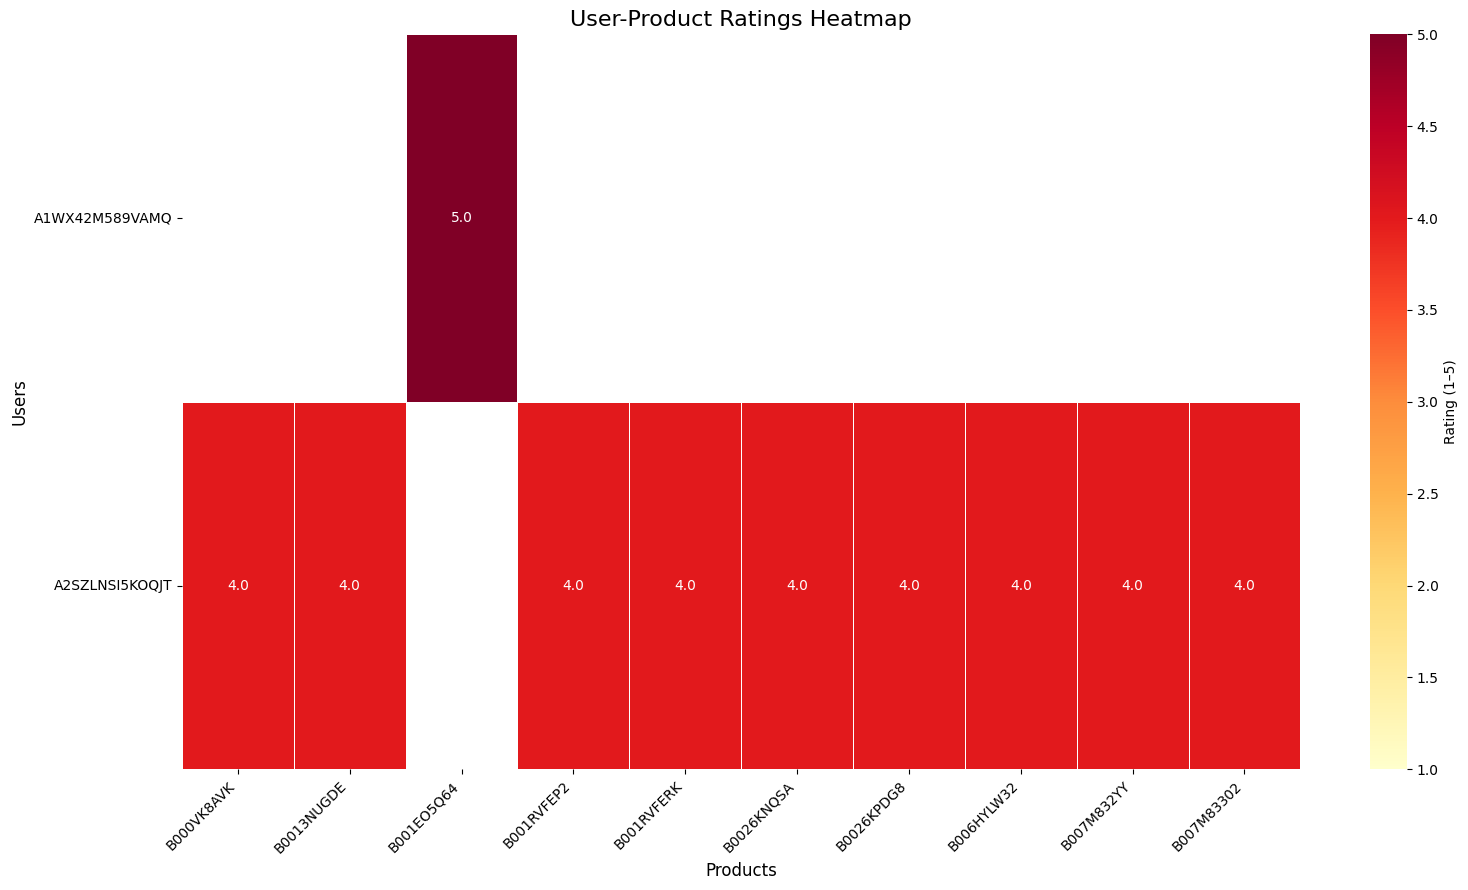

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload the CSV file
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# Choose the 20 most-rated products and 20 most-active users
top_products = df["ProductId"].value_counts().head(20).index
top_users = df["UserId"].value_counts().head(20).index

sample = df[
    df["ProductId"].isin(top_products) &
    df["UserId"].isin(top_users)
]

# Build the heatmap matrix
matrix = sample.pivot_table(
    index="UserId",
    columns="ProductId",
    values="Score",
    aggfunc="mean"
)

# Draw the heatmap
plt.figure(figsize=(16, 9))

sns.heatmap(
    matrix,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    vmin=1,
    vmax=5,
    cbar_kws={"label": "Rating (1–5)"}
)

plt.title("User-Product Ratings Heatmap", fontsize=16)
plt.xlabel("Products", fontsize=12)
plt.ylabel("Users", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Display the drawing
plt.show()

In [19]:
from IPython.display import display, HTML

display(HTML("""
<div style="height:600px; overflow-y:auto; overflow-x:auto;
            border:1px solid #ccc; padding:10px;">
  <img src="heatmap.png" style="max-width:none; width:1200px;">
</div>
"""))

Saving updated_ratings.csv to updated_ratings (3).csv


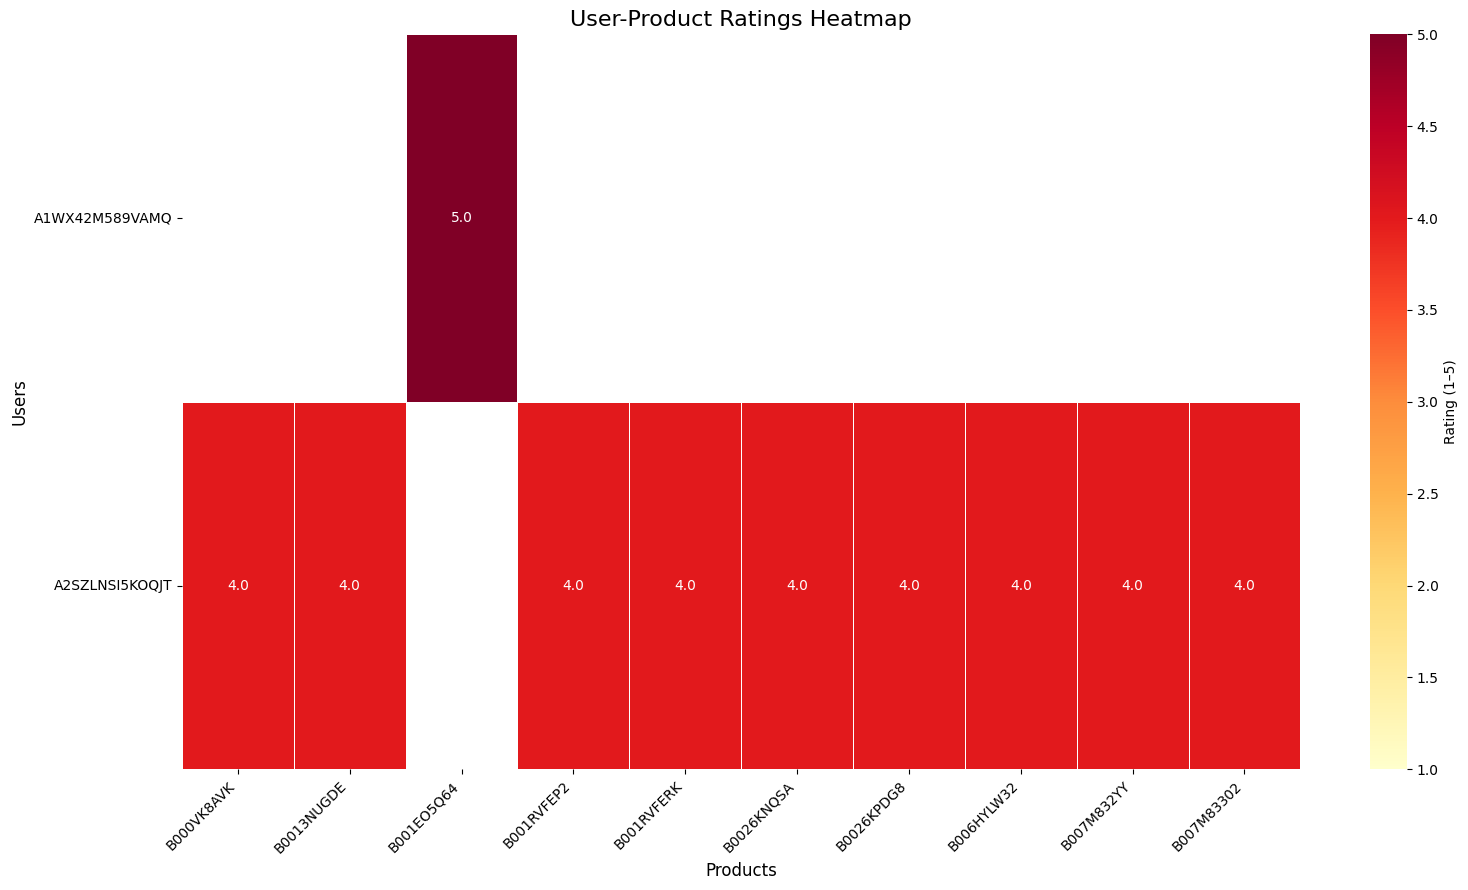

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload the CSV file
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# Choose the 20 most-rated products and 20 most-active users
top_products = df["ProductId"].value_counts().head(20).index
top_users = df["UserId"].value_counts().head(20).index

sample = df[
    df["ProductId"].isin(top_products) &
    df["UserId"].isin(top_users)
]

# Build the heatmap matrix
matrix = sample.pivot_table(
    index="UserId",
    columns="ProductId",
    values="Score",
    aggfunc="mean"
)

# Draw the heatmap
plt.figure(figsize=(16, 9))

sns.heatmap(
    matrix,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    vmin=1,
    vmax=5,
    cbar_kws={"label": "Rating (1–5)"}
)

plt.title("User-Product Ratings Heatmap", fontsize=16)
plt.xlabel("Products", fontsize=12)
plt.ylabel("Users", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Display the drawing
plt.show()